# Segmentación de inmuebles en arriendo con algoritmos no supervisados — Parte 3
### SVD y clustering jerárquico: dos técnicas complementarias

---

**Universidad de Cundinamarca** — Esp. Inteligencia Artificial

**CADI:** Introducción a Machine Learning · Período 2026-2

**Estudiante:** Ruby Dayana Cárdenas Gómez

**Docente:** Ing. Wilson Rojas Reales, PhD(c)

**Repositorio GitHub:** `https://github.com/RubyDayana/ml-no-supervisado-inmuebles.git`

---

### ¿Qué se hace en este notebook?

Los notebooks 1 y 2 resolvieron lo que pide el enunciado de la actividad (K-Means y PCA). Este notebook completa
la cobertura de los temas del curso con las otras dos técnicas de la semana 9 y 11: la **descomposición en valores
singulares (SVD)** y el **clustering jerárquico**, aplicadas al mismo dataset de inmuebles.

**Parte A — SVD**

1. Descomponer la matriz de datos con `numpy.linalg.svd` y demostrar que **PCA es una SVD** de los datos centrados.
2. Ver qué diferencia hay entre `PCA` y `TruncatedSVD` de scikit-learn.
3. Aproximar la matriz con pocos valores singulares (aproximación de bajo rango) y medir el error.
4. La aplicación clásica de SVD que menciona el curso: **comprimir una imagen**.

**Parte B — Clustering jerárquico**

5. Construir la jerarquía de agrupaciones (aglomerativa) con cuatro criterios de enlace y compararlos.
6. Leer un **dendrograma** y decidir dónde cortarlo.
7. Comparar el resultado con K-Means y comprobar si el clustering jerárquico sufre el mismo problema del notebook 2.

### Glosario rápido

| Término | Qué significa aquí |
|---|---|
| **SVD** | Toda matriz *A* se puede escribir como *A* = *U* Σ *Vᵀ*: dos matrices de direcciones (*U* y *V*) y los **valores singulares** de Σ, que miden la importancia de cada dirección. |
| **Aproximación de bajo rango** | Quedarse solo con los *k* valores singulares más grandes: es la mejor aproximación posible de *A* con *k* "capas" (teorema de Eckart–Young). |
| **Clustering aglomerativo** | Empieza con cada inmueble como su propio grupo y va uniendo los dos grupos más cercanos hasta que queda uno solo. |
| **Enlace (linkage)** | La regla para medir la distancia entre dos grupos: *single* (el par más cercano), *complete* (el par más lejano), *average* (el promedio) o *Ward* (el que menos aumenta la varianza interna). |
| **Dendrograma** | El árbol que registra el orden de las uniones; la altura de cada unión es la distancia a la que ocurrió. |

In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
SEMILLA = 42

URL_DATOS = ("https://raw.githubusercontent.com/RubyDayana/ml-no-supervisado-inmuebles/"
             "main/datos/DATASET_Inmuebles.xlsx")
RUTA = "datos/DATASET_Inmuebles.xlsx"

# Nombres limpios para las 10 columnas del Excel (el encabezado original trae un error de digitación
# en "Antigüedad" y la columna "Estrato" aparece dos veces).
NOMBRES = ["Inmueble", "Area_m2", "Habitaciones", "Estrato", "Precio_arriendo", "Banos",
           "Antiguedad_anios", "Localidad", "Tipo_inmueble", "Estrato_2"]


def cargar_crudo():
    """Lee el Excel del docente. Si no está en la carpeta datos/ (por ejemplo en Colab), lo descarga del repositorio."""
    if not os.path.exists(RUTA):
        os.makedirs("datos", exist_ok=True)
        urllib.request.urlretrieve(URL_DATOS, RUTA)
    return pd.read_excel(RUTA)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score, adjusted_rand_score

df = cargar_crudo()
df.columns = NOMBRES
df = df.drop(columns="Estrato_2")       # columna duplicada sin información (ver notebook 1)
df["Precio_m2"] = df["Precio_arriendo"] / df["Area_m2"]

COLORES = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

def ordenar_por_precio(etiquetas):
    """Renumera los clusters de menor a mayor precio promedio (0 = el más económico)."""
    s = pd.Series(df["Precio_arriendo"].values)
    orden = s.groupby(np.asarray(etiquetas)).mean().sort_values().index
    mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
    return np.array([mapa[e] for e in etiquetas])

print(df.shape, "inmuebles y columnas")

(1000, 10) inmuebles y columnas


---
# Parte A — SVD (descomposición en valores singulares)

## 1. PCA es una SVD

Se parte de la misma matriz preprocesada del notebook 2: las 5 variables numéricas estandarizadas y las 3
columnas de la localidad (1 000 × 8). PCA trabaja con los datos **centrados** (con media cero en cada columna).
Si *Xc* es esa matriz centrada y se calcula su SVD, *Xc* = *U* Σ *Vᵀ*, entonces:

- las filas de *Vᵀ* son las **direcciones de los componentes principales**,
- las coordenadas de los inmuebles en esos componentes son *U* Σ,
- y la varianza de cada componente es σ² / (*n* − 1), donde σ es el valor singular.

Es decir, PCA no es una técnica distinta: es una SVD de los datos centrados. Se comprueba numéricamente.

In [2]:
numericas = ["Precio_arriendo", "Area_m2", "Habitaciones", "Banos", "Antiguedad_anios"]
prep = ColumnTransformer([("n", StandardScaler(), numericas),
                          ("c", OneHotEncoder(), ["Localidad"])])
X8 = prep.fit_transform(df[numericas + ["Localidad"]])
nombres_cols = numericas + list(prep.named_transformers_["c"].get_feature_names_out())

n = X8.shape[0]
Xc = X8 - X8.mean(axis=0)                       # centrar: restar la media de cada columna

U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
print("Forma de Xc :", Xc.shape)
print("Forma de U  :", U.shape, "   (1 000 inmuebles x 8 direcciones)")
print("Forma de s  :", s.shape, "      (8 valores singulares)")
print("Forma de Vt :", Vt.shape, "      (8 componentes x 8 variables)")
print()
print("Valores singulares:", s.round(3))
print("Comprobación Xc = U·diag(s)·Vt ->  error máximo:", float(np.abs(Xc - (U * s) @ Vt).max()))

Forma de Xc : (1000, 8)
Forma de U  : (1000, 8)    (1 000 inmuebles x 8 direcciones)
Forma de s  : (8,)       (8 valores singulares)
Forma de Vt : (8, 8)       (8 componentes x 8 variables)

Valores singulares: [50.557 31.721 31.51  18.324 18.228 15.639 14.105  0.   ]
Comprobación Xc = U·diag(s)·Vt ->  error máximo: 8.493206138382448e-15


In [3]:
pca = PCA().fit(X8)

var_svd = s ** 2 / (n - 1)
print("Varianza de cada componente")
print(pd.DataFrame({"σ²/(n−1) (SVD)": var_svd, "PCA (scikit-learn)": pca.explained_variance_}).round(4).T.to_string())
print()
print("Diferencia máxima en las varianzas        :", float(np.abs(var_svd - pca.explained_variance_).max()))

# Los componentes pueden diferir en el signo (un eje y su opuesto son equivalentes), por eso se compara el valor absoluto
print("Diferencia máxima en las direcciones |Vt| :", float(np.abs(np.abs(Vt[:3]) - np.abs(pca.components_[:3])).max()))
print("Diferencia máxima en las coordenadas |UΣ| :", float(np.abs(np.abs((U * s)[:, :3]) - np.abs(pca.transform(X8)[:, :3])).max()))

Varianza de cada componente
                         0       1       2       3       4       5       6    7
σ²/(n−1) (SVD)      2.5585  1.0072  0.9939  0.3361  0.3326  0.2448  0.1991  0.0
PCA (scikit-learn)  2.5585  1.0072  0.9939  0.3361  0.3326  0.2448  0.1991  0.0

Diferencia máxima en las varianzas        : 2.0816681711721685e-15
Diferencia máxima en las direcciones |Vt| : 7.960299086562372e-14
Diferencia máxima en las coordenadas |UΣ| : 2.103317520152359e-13


**Lectura de los resultados.** La reconstrucción *U*·Σ·*Vᵀ* reproduce la matriz centrada con un error de 8.5 × 10⁻¹⁵,
es decir, cero a efectos prácticos. Las varianzas σ²/(*n* − 1) coinciden con `explained_variance_` de `PCA` (diferencia
máxima de 2 × 10⁻¹⁵) y las direcciones y coordenadas coinciden salvo el signo (diferencias del orden de 10⁻¹³). Queda
demostrado numéricamente que **PCA es una SVD de los datos centrados**: el componente 1 tiene varianza 2.56 (45.1 % de
la total) y los tres primeros suman 80.4 %.

El último valor singular es **0**. No es un error: las tres columnas de localidad suman siempre 1, de modo que la
tercera se puede deducir de las otras dos (colinealidad exacta) y la matriz tiene rango 7, no 8. Es la misma razón por la
que el octavo componente del notebook 2 no explicaba nada.

### 1.1. `PCA` frente a `TruncatedSVD`

Scikit-learn tiene dos clases parecidas. `PCA` **centra** los datos antes de descomponer. `TruncatedSVD` descompone
la matriz **tal como viene**, sin centrar; está pensada para matrices muy grandes y dispersas (por ejemplo, texto),
donde restar la media destruiría la dispersión. Si los datos **no** están centrados, el primer componente de
`TruncatedSVD` tiende a apuntar hacia la media de las columnas en lugar de capturar solo la variación. Con la matriz
de este notebook ese efecto no aparece (las columnas numéricas ya están estandarizadas, es decir, centradas), así que
se prueba también con una matriz que **sí** tiene media distinta de cero: las cuatro variables informativas
escaladas al rango [0, 1].

In [4]:
pca2 = PCA(n_components=2).fit(X8)
tsvd_sin_centrar = TruncatedSVD(n_components=2, random_state=42).fit(X8)
tsvd_centrado = TruncatedSVD(n_components=2, random_state=42).fit(Xc)

tabla = pd.DataFrame({
    "PCA (centra por dentro)": pca2.explained_variance_ratio_,
    "TruncatedSVD sin centrar": tsvd_sin_centrar.explained_variance_ratio_,
    "TruncatedSVD sobre datos centrados": tsvd_centrado.explained_variance_ratio_,
}, index=["Componente 1", "Componente 2"]).round(4)
print("Proporción de varianza explicada")
print(tabla.to_string())
print()
print("Cargas del componente 1 de TruncatedSVD sin centrar:")
print(pd.Series(tsvd_sin_centrar.components_[0], index=nombres_cols).round(3).to_string())

Proporción de varianza explicada
              PCA (centra por dentro)  TruncatedSVD sin centrar  TruncatedSVD sobre datos centrados
Componente 1                   0.4511                    0.4511                              0.4511
Componente 2                   0.1776                    0.1776                              0.1776

Cargas del componente 1 de TruncatedSVD sin centrar:
Precio_arriendo        0.582
Area_m2                0.574
Habitaciones           0.573
Banos                  0.022
Antiguedad_anios      -0.037
Localidad_Chapinero   -0.011
Localidad_Suba        -0.017
Localidad_Usaquén      0.028


In [5]:
from sklearn.preprocessing import MinMaxScaler

X_mm = MinMaxScaler().fit_transform(df[["Area_m2", "Habitaciones", "Estrato", "Precio_arriendo"]])   # valores en [0, 1], media > 0
print("Media de cada columna:", X_mm.mean(axis=0).round(3))

pca_mm = PCA(n_components=2).fit(X_mm)
tsvd_mm = TruncatedSVD(n_components=2, random_state=42).fit(X_mm)
print()
print("Varianza explicada, componente 1 y 2")
print("  PCA (centra)          :", pca_mm.explained_variance_ratio_.round(4))
print("  TruncatedSVD (no centra):", tsvd_mm.explained_variance_ratio_.round(4))
print()
print("Componente 1 de PCA          :", pca_mm.components_[0].round(3))
print("Componente 1 de TruncatedSVD :", tsvd_mm.components_[0].round(3))
print("Correlación del puntaje 1 de TruncatedSVD con el promedio de la fila:",
      round(float(np.corrcoef(tsvd_mm.transform(X_mm)[:, 0], X_mm.mean(axis=1))[0, 1]), 3))

Media de cada columna: [0.351 0.416 0.489 0.354]

Varianza explicada, componente 1 y 2
  PCA (centra)          : [0.8564 0.058 ]
  TruncatedSVD (no centra): [0.8559 0.0581]

Componente 1 de PCA          : [0.439 0.502 0.584 0.463]
Componente 1 de TruncatedSVD : [0.435 0.509 0.596 0.444]
Correlación del puntaje 1 de TruncatedSVD con el promedio de la fila: 1.0


**Lectura de los resultados.** Con la matriz de la parte principal las tres columnas de la tabla son idénticas
(45.11 % y 17.76 %), porque las variables numéricas ya tienen media cero y `TruncatedSVD` no tiene nada que "arreglar".
Con las variables en [0, 1] sí hay diferencia, aunque pequeña: `TruncatedSVD` da 85.59 % para el primer componente frente
a 85.64 % de `PCA`, y sus cargas cambian ligeramente (por ejemplo, 0.444 frente a 0.463 en precio). La correlación de 1.000
entre su puntaje y el promedio de cada fila indica que ese primer componente funciona como un "tamaño general" del
inmueble. **Conclusión práctica:** con datos densos y de tamaño moderado como estos, la herramienta correcta es `PCA`;
`TruncatedSVD` se reserva para matrices enormes o dispersas, o hay que centrar los datos antes.

### 1.2. Aproximación de bajo rango

Si se reconstruye la matriz con solo los *k* primeros valores singulares, *Xc*ₖ = *U*ₖ Σₖ *V*ₖᵀ, se obtiene la mejor
aproximación posible de rango *k* (teorema de Eckart–Young). El error relativo de la reconstrucción es
precisamente la fracción de varianza que **no** explican los componentes descartados.

   Varianza conservada (%)  Error relativo (%)  1 − varianza acumulada PCA (%)
k                                                                             
1                   45.106              54.894                          54.894
2                   62.862              37.138                          37.138
3                   80.384              19.616                          19.616
4                   86.309              13.691                          13.691
5                   92.173               7.827                           7.827
6                   96.489               3.511                           3.511
7                  100.000               0.000                           0.000
8                  100.000               0.000                           0.000


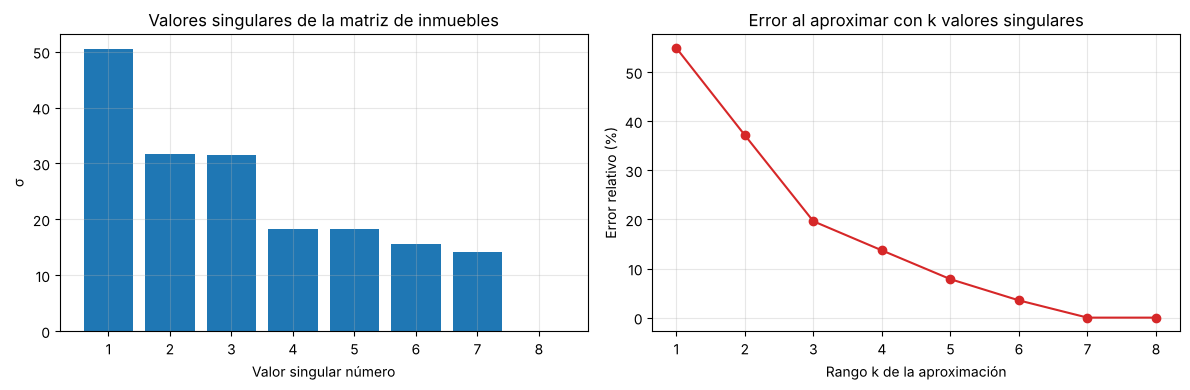

In [6]:
filas = []
for k in range(1, 9):
    Xk = (U[:, :k] * s[:k]) @ Vt[:k]
    error_rel = np.linalg.norm(Xc - Xk) ** 2 / np.linalg.norm(Xc) ** 2
    filas.append({"k": k, "Varianza conservada (%)": (1 - error_rel) * 100,
                  "Error relativo (%)": error_rel * 100,
                  "1 − varianza acumulada PCA (%)": (1 - pca.explained_variance_ratio_[:k].sum()) * 100})
tabla_rk = pd.DataFrame(filas).set_index("k").round(3)
print(tabla_rk.to_string())

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].bar(range(1, 9), s, color="tab:blue")
ejes[0].set(xlabel="Valor singular número", ylabel="σ", title="Valores singulares de la matriz de inmuebles")
ejes[1].plot(tabla_rk.index, tabla_rk["Error relativo (%)"], marker="o", color="tab:red")
ejes[1].set(xlabel="Rango k de la aproximación", ylabel="Error relativo (%)", title="Error al aproximar con k valores singulares")
plt.tight_layout(); plt.show()

**Lectura de los resultados.** El error relativo de la aproximación de rango *k* es exactamente 1 − (varianza acumulada
de PCA): las dos últimas columnas de la tabla coinciden en cada fila. Con *k* = 2 se conserva 62.9 %; con *k* = 3, 80.4 %;
con *k* = 6, 96.5 %, y con *k* = 7 el 100 % (el octavo valor singular es 0). Es el teorema de Eckart–Young en acción:
ninguna otra matriz de rango *k* se acerca más a los datos. En el gráfico de barras se ven los valores singulares
50.6, 31.7 y 31.5 casi iguales entre sí en el segundo y tercer lugar (los componentes 2 y 3 son casi
intercambiables, como se anotó en el notebook 2), seguidos de un grupo de cinco valores mucho menores.

## 2. Aplicación clásica: comprimir una imagen con SVD

Una imagen en escala de grises es una matriz de números (cada celda, la luminosidad de un píxel). Al aplicarle SVD y
conservar solo los *k* primeros valores singulares se guarda **mucho menos información** que la imagen completa. Una
matriz de *m* × *n* ocupa *m·n* números; su aproximación de rango *k* ocupa *k·(m + n + 1)*. Se prueba con la imagen
de muestra `china.jpg` que incluye scikit-learn.

Imagen: 427 x 640 píxeles = 273,280 números; rango máximo 427

   k    Números guardados  % del original   Energía conservada   Error RMS (niveles de gris)
   5                5,340            2.0%               96.52%                         31.12
  20               21,360            7.8%               98.08%                         23.10
  50               53,400           19.5%               98.92%                         17.36
 100              106,800           39.1%               99.45%                         12.37


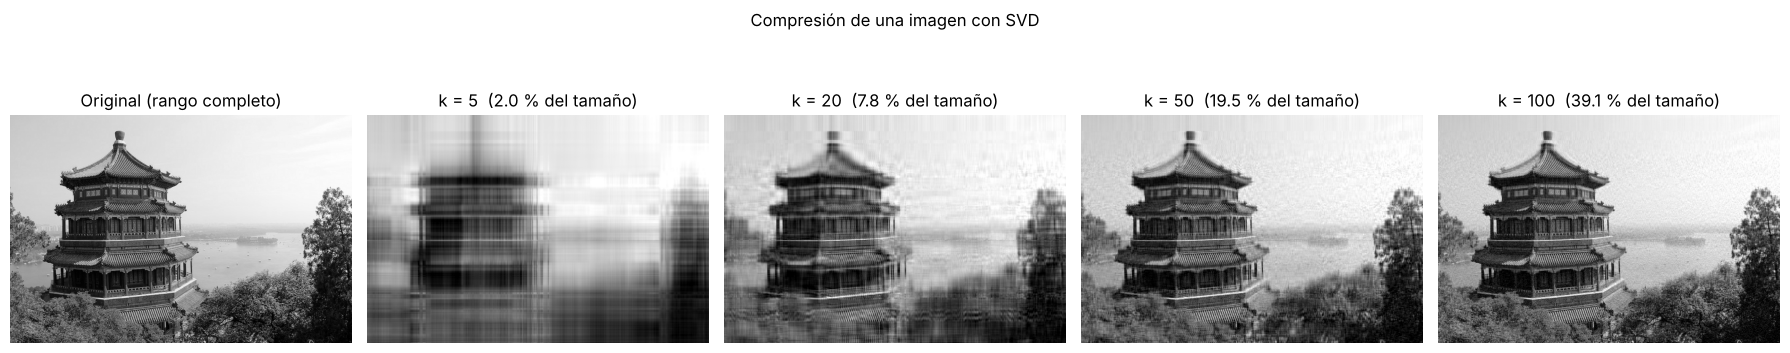

In [7]:
from sklearn.datasets import load_sample_image

color = load_sample_image("china.jpg")
gris = color.astype(float) @ np.array([0.299, 0.587, 0.114])          # a escala de grises
m, nn = gris.shape
Ui, si, Vti = np.linalg.svd(gris, full_matrices=False)

energia = np.cumsum(si ** 2) / np.sum(si ** 2)
ks = [5, 20, 50, 100]
print(f"Imagen: {m} x {nn} píxeles = {m * nn:,} números; rango máximo {len(si)}")
print()
print(f"{'k':>4} {'Números guardados':>20} {'% del original':>15} {'Energía conservada':>20} {'Error RMS (niveles de gris)':>29}")
for k in ks:
    rec = (Ui[:, :k] * si[:k]) @ Vti[:k]
    guardados = k * (m + nn + 1)
    rms = np.sqrt(np.mean((gris - rec) ** 2))
    print(f"{k:>4} {guardados:>20,} {guardados / (m * nn) * 100:>14.1f}% {energia[k - 1] * 100:>19.2f}% {rms:>29.2f}")

fig, ejes = plt.subplots(1, 5, figsize=(18, 3.8))
ejes[0].imshow(gris, cmap="gray", vmin=0, vmax=255); ejes[0].set_title("Original (rango completo)")
for eje, k in zip(ejes[1:], ks):
    rec = np.clip((Ui[:, :k] * si[:k]) @ Vti[:k], 0, 255)
    eje.imshow(rec, cmap="gray", vmin=0, vmax=255)
    eje.set_title(f"k = {k}  ({k * (m + nn + 1) / (m * nn) * 100:.1f} % del tamaño)")
for eje in ejes:
    eje.axis("off")
plt.suptitle("Compresión de una imagen con SVD", y=1.03)
plt.tight_layout(); plt.show()

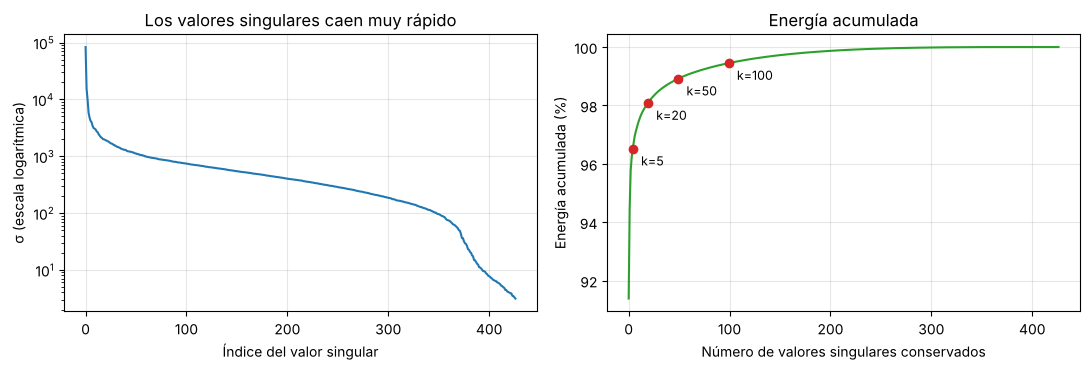

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].semilogy(si, color="tab:blue")
ejes[0].set(xlabel="Índice del valor singular", ylabel="σ (escala logarítmica)", title="Los valores singulares caen muy rápido")
ejes[1].plot(energia * 100, color="tab:green")
for k in ks:
    ejes[1].scatter(k - 1, energia[k - 1] * 100, color="tab:red", zorder=5)
    ejes[1].annotate(f"k={k}", (k - 1, energia[k - 1] * 100), textcoords="offset points", xytext=(6, -12), fontsize=9)
ejes[1].set(xlabel="Número de valores singulares conservados", ylabel="Energía acumulada (%)", title="Energía acumulada")
plt.tight_layout(); plt.show()

**Lectura de los resultados.** La imagen de 427 × 640 píxeles necesita 273 280 números. Con solo **5** valores singulares
se guarda el 2.0 % de esa cantidad (5 340 números) y ya se conserva el 96.52 % de la "energía"; la imagen se reconoce
pero se ve borrosa (error RMS de 31.1 niveles de gris sobre 255). Con **20** valores (7.8 % del tamaño) la energía es
98.08 % y se distinguen los detalles principales; con **50** (19.5 %) el error baja a 17.4 y con **100** (39.1 %) a 12.4.

Los valores singulares caen de forma muy rápida (gráfico en escala logarítmica): unos pocos concentran casi toda la
información y el resto aporta detalle fino. Por eso SVD sirve para comprimir. Conviene notar que la "energía" es una
medida global: aun con 99.45 % (k = 100) queda un error visible en los bordes, y el ahorro de espacio solo existe
mientras *k*·(*m* + *n* + 1) sea menor que *m*·*n*, es decir, para *k* menor que 255 en esta imagen.

---
# Parte B — Clustering jerárquico

## 3. La jerarquía de agrupaciones

K-Means exige decidir el número de grupos antes de empezar. El **clustering jerárquico aglomerativo** no: construye
**todos** los agrupamientos posibles (de 1 000 grupos a uno solo) y el número de grupos se decide después, cortando el
árbol. Se usa sobre las cuatro variables informativas del notebook 1 (área, habitaciones, estrato y precio),
estandarizadas, para poder comparar con el K-Means de allí.

Como el criterio de enlace cambia mucho el resultado, se comparan cuatro. Para evaluar cada jerarquía se usa el
**coeficiente de correlación cofenética** (qué tan fielmente el árbol conserva las distancias originales entre
inmuebles; más alto es mejor) y la silueta de un corte en 3 grupos.

In [9]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

VAR_INF = ["Area_m2", "Habitaciones", "Estrato", "Precio_arriendo"]
X_inf = StandardScaler().fit_transform(df[VAR_INF])
distancias = pdist(X_inf)                      # distancias euclídeas entre los 1 000 inmuebles (499 500 pares)

enlaces = {}
filas = []
for metodo in ["single", "complete", "average", "ward"]:
    Z = linkage(X_inf, method=metodo)
    enlaces[metodo] = Z
    et = fcluster(Z, t=3, criterion="maxclust") - 1
    filas.append({
        "Enlace": metodo,
        "Correlación cofenética": cophenet(Z, distancias)[0],
        "Silueta (corte en 3)": silhouette_score(X_inf, et),
        "Tamaños de los 3 grupos": sorted(np.bincount(et).tolist(), reverse=True),
    })
tabla_enlaces = pd.DataFrame(filas).set_index("Enlace")
tabla_enlaces["Correlación cofenética"] = tabla_enlaces["Correlación cofenética"].round(3)
tabla_enlaces["Silueta (corte en 3)"] = tabla_enlaces["Silueta (corte en 3)"].round(3)
tabla_enlaces

,Correlación cofenética,Silueta (corte en 3),Tamaños de los 3 grupos
Enlace,,,
single,0.449,0.327,"[735, 144, 121]"
complete,0.872,0.467,"[618, 202, 180]"
average,0.874,0.455,"[618, 226, 156]"
ward,0.862,0.477,"[419, 382, 199]"


**Lectura de los resultados.** El enlace **single** es claramente el peor: correlación cofenética de 0.449 y un
grupo gigante de 735 inmuebles junto a dos pequeños (el efecto "cadena": une inmuebles vecinos uno a uno y arrastra
todo). Los otros tres enlaces conservan bien las distancias (0.862–0.874). *Average* y *complete* tienen la mayor
correlación cofenética (0.874 y 0.872) pero grupos muy desiguales (618 / 202 / 180 y 618 / 226 / 156), mientras que
**Ward** logra la mejor silueta (0.477) y los grupos más equilibrados (419 / 382 / 199). Se elige Ward por el
equilibrio y porque su criterio (minimizar la varianza interna) es el mismo que optimiza K-Means.

### 3.1. El dendrograma (enlace de Ward)

El enlace de **Ward** une en cada paso los dos grupos cuya unión aumenta menos la varianza interna; es el criterio
más parecido a K-Means y el que suele dar grupos compactos y de tamaño equilibrado. Con 1 000 hojas el
dendrograma completo es ilegible; se muestran las últimas 30 uniones (`truncate_mode="lastp"`), donde cada hoja
es un grupo ya formado y su tamaño aparece entre paréntesis.

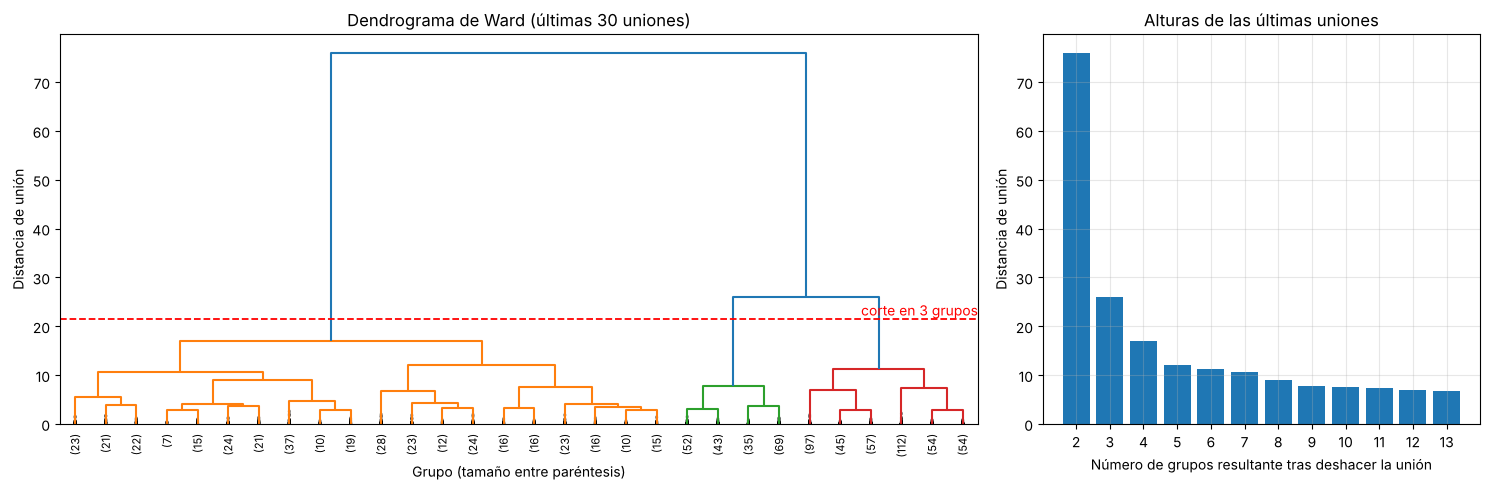

Alturas de las últimas uniones (de la última hacia atrás): [75.96, 26.05, 17.03, 12.03, 11.31, 10.74, 9.01, 7.79, 7.55, 7.37, 7.01, 6.75]
Saltos entre una unión y la siguiente: [49.9, 9.02, 5.01, 0.72, 0.57, 1.73, 1.21, 0.24, 0.18, 0.36, 0.26]


In [10]:
Zw = enlaces["ward"]

fig, ejes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.1, 1]})
dendrogram(Zw, truncate_mode="lastp", p=30, ax=ejes[0], color_threshold=Zw[-3, 2] + 1e-6,
           leaf_rotation=90, leaf_font_size=8, show_contracted=True)
corte3 = (Zw[-3, 2] + Zw[-2, 2]) / 2
ejes[0].axhline(corte3, color="red", ls="--", lw=1.3)
ejes[0].text(ejes[0].get_xlim()[1], corte3, "  corte en 3 grupos", color="red", va="bottom", ha="right")
ejes[0].set(title="Dendrograma de Ward (últimas 30 uniones)", xlabel="Grupo (tamaño entre paréntesis)", ylabel="Distancia de unión")
ejes[0].grid(False)

alturas = Zw[-12:, 2][::-1]                      # alturas de las 12 últimas uniones, de la última a la anterior
ejes[1].bar(range(2, 14), alturas, color="tab:blue")
ejes[1].set(xlabel="Número de grupos resultante tras deshacer la unión", ylabel="Distancia de unión",
            title="Alturas de las últimas uniones")
ejes[1].set_xticks(range(2, 14))
plt.tight_layout(); plt.show()

print("Alturas de las últimas uniones (de la última hacia atrás):", alturas.round(2).tolist())
print("Saltos entre una unión y la siguiente:", (-np.diff(alturas)).round(2).tolist())

**Lectura de los resultados.** La unión final ocurre a una distancia de 75.96 y la anterior a 26.05: ese salto de 49.9
es, por mucho, el mayor, y sugiere que los datos tienen **dos** bloques muy separados (inmuebles pequeños y
grandes). El siguiente salto notable es de 9.02 (de 26.05 a 17.03), que justifica un corte en **tres** grupos (línea roja);
los saltos posteriores son pequeños (5.0, 0.7, 0.6, …) y no apoyan separar más. Es la misma conclusión del notebook 1:
k = 2 es la partición más clara, k = 3 la más útil comercialmente.

## 4. Cortar el árbol: k = 2, 3 y 4

Cortar el dendrograma a una altura equivale a elegir el número de grupos. Se cortan 2, 3 y 4 grupos con Ward, se
renumeran por precio como en los notebooks anteriores y se comparan sus perfiles con los de K-Means.

In [11]:
resultados = {}
for k in (2, 3, 4):
    resultados[k] = ordenar_por_precio(fcluster(Zw, t=k, criterion="maxclust") - 1)
    df[f"ward_k{k}"] = resultados[k]

for k in (2, 3, 4):
    t = df.groupby(f"ward_k{k}").agg(Inmuebles=("Inmueble", "count"), Area_m2=("Area_m2", "mean"),
                                       Habitaciones=("Habitaciones", "mean"), Estrato=("Estrato", "mean"),
                                       Precio_arriendo=("Precio_arriendo", "mean"), Precio_m2=("Precio_m2", "mean")).round(1)
    print(f"===== Jerárquico (Ward), k = {k}  |  silueta {silhouette_score(X_inf, resultados[k]):.3f} =====")
    print(t.to_string())
    print()

===== Jerárquico (Ward), k = 2  |  silueta 0.611 =====
         Inmuebles  Area_m2  Habitaciones  Estrato  Precio_arriendo  Precio_m2
ward_k2                                                                       
0              618     61.0           1.8      3.0        1984490.1    33305.1
1              382    154.6           4.0      5.5        6300711.6    43657.0

===== Jerárquico (Ward), k = 3  |  silueta 0.477 =====
         Inmuebles  Area_m2  Habitaciones  Estrato  Precio_arriendo  Precio_m2
ward_k3                                                                       
0              419     49.7           1.5      2.5        1469201.9    31406.4
1              199     84.8           2.5      4.0        3069443.5    37303.0
2              382    154.6           4.0      5.5        6300711.6    43657.0

===== Jerárquico (Ward), k = 4  |  silueta 0.419 =====
         Inmuebles  Area_m2  Habitaciones  Estrato  Precio_arriendo  Precio_m2
ward_k4                                    

**Lectura de los resultados.** Con *k* = 2, la silueta es 0.611 (la más alta): 618 inmuebles pequeños y económicos
(61 m², estrato 3, 1.98 millones) frente a 382 grandes (155 m², estrato 5.5, 6.30 millones). Con *k* = 3 el bloque
pequeño se divide en 419 inmuebles básicos (50 m², 1.47 millones) y 199 intermedios (85 m², 3.07 millones), y el grupo
grande queda intacto (382, 6.30 millones); la silueta baja a 0.477. Con *k* = 4 el grupo grande se parte en 183
inmuebles de 120 m² y 199 de 186 m² con precios casi iguales (6.13 y 6.46 millones), pero un precio por m² muy distinto
(52 782 frente a 35 265 $/m²): hay un nicho de inmuebles medianos con alquiler caro por metro cuadrado. La silueta baja a
0.419. Se recomienda **k = 3** como segmentación base y k = 4 solo si el negocio quiere distinguir ese nicho.

### 4.1. Jerárquico frente a K-Means

Se comparan los tres grupos de Ward con los de K-Means (k = 3, mismas variables) con el ARI, una tabla cruzada y el
plano PC1–PC2 de las cuatro variables. Además se comprueba que `AgglomerativeClustering` de scikit-learn da el mismo
resultado que `scipy`.

scikit-learn (AgglomerativeClustering) vs. scipy (linkage): ARI = 1.000

Ward (k = 3) vs. K-Means (k = 3): ARI = 0.975
Inmuebles que cambian de grupo: 10 de 1000

Tabla cruzada (filas = Ward, columnas = K-Means):
K-Means    0    1    2
Ward                  
0        419    0    0
1          0  199    0
2          0   10  372


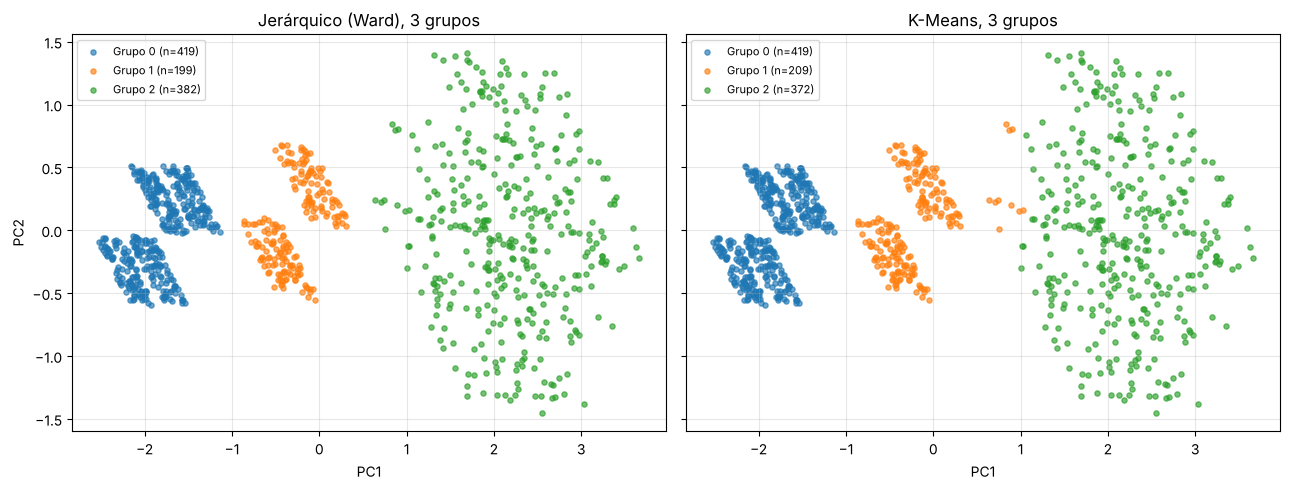

In [12]:
km3 = ordenar_por_precio(KMeans(3, random_state=42, n_init=10).fit_predict(X_inf))
df["kmeans_k3"] = km3
ward3 = resultados[3]

sk_ward3 = ordenar_por_precio(AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_inf))
print(f"scikit-learn (AgglomerativeClustering) vs. scipy (linkage): ARI = {adjusted_rand_score(ward3, sk_ward3):.3f}")
print()
print(f"Ward (k = 3) vs. K-Means (k = 3): ARI = {adjusted_rand_score(ward3, km3):.3f}")
print(f"Inmuebles que cambian de grupo: {(ward3 != km3).sum()} de {len(df)}")
print()
print("Tabla cruzada (filas = Ward, columnas = K-Means):")
print(pd.crosstab(pd.Series(ward3, name="Ward"), pd.Series(km3, name="K-Means")))

pc = PCA(n_components=2).fit_transform(X_inf)
fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for eje, et, titulo in zip(ejes, (ward3, km3), ("Jerárquico (Ward), 3 grupos", "K-Means, 3 grupos")):
    for g in range(3):
        m = et == g
        eje.scatter(pc[m, 0], pc[m, 1], s=14, alpha=0.65, color=COLORES[g], label=f"Grupo {g} (n={m.sum()})")
    eje.set(xlabel="PC1", title=titulo); eje.legend(fontsize=8)
ejes[0].set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Lectura de los resultados.** `AgglomerativeClustering` de scikit-learn y `linkage` de scipy dan exactamente la misma
partición (ARI = 1.000). Ward y K-Means con *k* = 3 coinciden casi por completo (ARI = 0.975): los grupos 0 (419) y 1
(199) son idénticos y solo **10 de 1 000 inmuebles** (los de la frontera entre el grupo intermedio y el de lujo)
cambian de grupo. Es esperable, porque ambos minimizan la varianza interna; lo que cambia es el procedimiento. K-Means
es más rápido en datasets grandes y el jerárquico entrega el árbol completo para decidir *k* después, a costa de memoria
(*n*² distancias) y de que una unión hecha no se puede deshacer.

### 4.2. ¿El clustering jerárquico también se equivoca con las variables ruidosas?

En el notebook 2 K-Means, al usar las 8 columnas, partía el bloque pequeño por el número de baños. Se repite el
experimento con Ward sobre las mismas 8 columnas preprocesadas.

In [13]:
Z8 = linkage(X8, method="ward")
ward8 = ordenar_por_precio(fcluster(Z8, t=3, criterion="maxclust") - 1)
df["ward8_k3"] = ward8

t = df.groupby("ward8_k3").agg(Inmuebles=("Inmueble", "count"), Area_m2=("Area_m2", "mean"),
                                Precio_arriendo=("Precio_arriendo", "mean"), Banos=("Banos", "mean"),
                                Antiguedad=("Antiguedad_anios", "mean")).round(2)
print("Ward sobre las 8 columnas preprocesadas, 3 grupos:")
print(t.to_string())
print()
print(f"ARI frente al Ward sobre las 4 variables informativas: {adjusted_rand_score(ward8, ward3):.3f}")

Ward sobre las 8 columnas preprocesadas, 3 grupos:
          Inmuebles  Area_m2  Precio_arriendo  Banos  Antiguedad
ward8_k3                                                        
0               301    62.59       2044250.40   2.00        8.49
1               334    62.24       2056868.96   1.00        8.57
2               365   156.44       6386227.62   1.49        8.33

ARI frente al Ward sobre las 4 variables informativas: 0.528


**Lectura de los resultados.** Ward también cae en la trampa: con las 8 columnas separa 301 inmuebles de 2 baños y
334 de 1 baño que tienen **prácticamente el mismo área (62.6 y 62.2 m²) y el mismo precio (2.04 y 2.06 millones)**. Es
una división sin valor comercial, que solo refleja una variable que no se relaciona con el precio. El ARI frente al
Ward sobre las 4 variables informativas baja a 0.528. La causa no es el algoritmo sino los datos: ni K-Means ni el
jerárquico saben qué variables importan para el negocio, y todos agrupan por lo que más varía tras estandarizar.

---

# Conclusiones del notebook

1. **PCA es una SVD.** Con los datos centrados, las varianzas, direcciones y coordenadas coinciden con las de
   `numpy.linalg.svd` hasta ~10⁻¹³; el valor singular nulo revela la colinealidad exacta de las tres columnas de localidad.
2. **`PCA` y `TruncatedSVD` solo difieren si los datos no están centrados.** Aquí la diferencia es mínima (85.59 % frente a
   85.64 %); para datos densos y moderados se usa `PCA`.
3. **La aproximación de bajo rango tiene un error medible y exacto:** es igual a la varianza no explicada. Con 3 valores
   singulares se conserva 80.4 % de la información de los inmuebles; con 6, 96.5 %.
4. **Comprimir una imagen con SVD funciona** porque los valores singulares decaen rápidamente: con 20 valores (7.8 % del
   tamaño) se conserva 98.08 % de la energía.
5. **En el clustering jerárquico el enlace importa:** *single* produce un grupo gigante y una pésima correlación cofenética
   (0.449); Ward es el más equilibrado (silueta 0.477).
6. **El dendrograma confirma lo visto con K-Means:** el mayor salto indica 2 bloques y el siguiente justifica 3 grupos;
   Ward y K-Means con *k* = 3 difieren en 10 de 1 000 inmuebles (ARI 0.975).
7. **Las variables irrelevantes dañan a cualquier algoritmo de agrupamiento:** con las 8 columnas, Ward también divide por
   número de baños (ARI 0.528 frente al resultado informativo). Seleccionar variables con criterio comercial es más
   importante que elegir entre K-Means y jerárquico.